
# MAAI901 – Vision Transformer for Skin Lesion Classification

## Section 1 – Introduction

**Purpose:** This project uses a pretrained Vision Transformer (ViT) to classify skin lesion images and evaluate its performance.

**Dataset:** HAM10000 contains 10,015 dermatoscopic images belonging to seven skin lesion categories (Tschandl et al., 2018).

**Task:** Classify each skin lesion image into one of the seven diagnostic categories.

**Why ViT?** Vision Transformers divide images into small patches and use self-attention to learn visual patterns (Dosovitskiy et al., 2021).

**Research Question:** Does fully fine-tuning a pretrained ViT improve skin lesion classification compared with training only its classification head?

**Evaluation:** The main metric is macro-F1 because the dataset is imbalanced. Melanoma recall is also measured because missing melanoma cases is an important clinical safety concern.


### Dataset Access and Reproducibility

This project uses the HAM10000 dataset, containing 10,015 dermatoscopic images across seven diagnostic categories (Tschandl, Rosendahl and Kittler, 2018).

**Dataset source:** https://doi.org/10.7910/DVN/DBW86T

To reproduce the experiment in Google Colab:

1. Download the HAM10000 dataset from the source above.
2. Create a folder named `HAM10000` in Google Drive under `MyDrive`.
3. Place `HAM10000_metadata.csv` and the two HAM10000 image folders inside it.
4. Open this notebook in Google Colab and select a GPU runtime.
5. Run the notebook cells sequentially.

The notebook expects the dataset at `/content/drive/MyDrive/HAM10000`. The dataset and model checkpoints are not included in the GitHub repository. Reported results were obtained using a fixed random seed of 42 and a single training run per model.


### 1.1 Setup and Configuration

Import the required libraries, set the random seed, and configure the GPU. `QUICK_TEST` is used to check the code before running the full experiment.


In [ ]:
import importlib.util
import subprocess
import sys

# Install missing libraries
for module, pip_name in {"transformers": "transformers", "seaborn": "seaborn"}.items():
    if importlib.util.find_spec(module) is None:
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
        except subprocess.CalledProcessError:
            print("Could not install:", pip_name)

import os
import random
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)

# Settings
QUICK_TEST = False
SEED = 42
IMG_SIZE = 224

# Save results permanently to Google Drive
from google.colab import drive
drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/HAM10000")

assert BASE.exists(), "HAM10000 folder not found in Google Drive"

FIG_DIR = BASE / "outputs" / "figures"
WEIGHTS_DIR = BASE / "weights"

for folder in (FIG_DIR, WEIGHTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)

plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.axisbelow": True
})

if QUICK_TEST:
    print("Quick test mode: testing with a small dataset")
else:
    print("Full experiment mode")

print("Project folder:", BASE)
print("Figures folder:", FIG_DIR)
print("Weights folder:", WEIGHTS_DIR)

Mounted at /content/drive
Full experiment mode
Project folder: /content/drive/MyDrive/HAM10000
Figures folder: /content/drive/MyDrive/HAM10000/outputs/figures
Weights folder: /content/drive/MyDrive/HAM10000/weights


In [ ]:
import shutil

total, used, free = shutil.disk_usage("/content/drive/MyDrive")

print("Google Drive free space:", round(free / (1024**3), 2), "GB")
print("Weights folder exists:", WEIGHTS_DIR.exists())
print("Outputs folder exists:", (BASE / "outputs").exists())

Google Drive free space: 0.89 GB
Weights folder exists: True
Outputs folder exists: True


In [ ]:
import torch
import torch.nn as nn
import torchvision
import transformers

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from transformers import ViTForImageClassification, ViTImageProcessor, get_cosine_schedule_with_warmup

# Set random seed
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

# Check library versions
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Transformers:", transformers.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

# Check GPU
if torch.cuda.is_available():
    print("Device:", torch.cuda.get_device_name(0))
else:
    print("Device: CPU")
    print("GPU not available. Select T4 GPU in Colab runtime settings.")

Python: 3.13.16
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Transformers: 5.20.2
Pandas: 2.2.3
NumPy: 2.1.3
Device: Tesla T4



## Section 2 – Dataset Loading and Exploration

This section loads the HAM10000 dataset and explores its images, class distribution and metadata.

**Dataset Location:** The dataset is stored in Google Drive under `MyDrive/HAM10000`. It contains 10,015 images and the metadata CSV file.

The dataset is used for academic research. The images will not be uploaded to GitHub.


In [ ]:
# Load HAM10000 dataset from Google Drive
DATA_DIR = BASE

df = pd.read_csv(DATA_DIR / "HAM10000_metadata.csv")
META_COLUMNS = list(df.columns)

# Find image files
image_paths = {}

for p in sorted(DATA_DIR.rglob("*.jpg")):
    image_paths[p.stem] = p

df["path"] = df["image_id"].map(image_paths)

print("Total images:", len(df))
print("Images found:", df["path"].notna().sum())

assert df["path"].notna().all(), "Some images are missing"

# Skin lesion categories
CLASS_NAMES = sorted(df["dx"].unique())

assert len(CLASS_NAMES) == 7, "Expected 7 classes"

FULL_NAMES = {
    "akiec": "Actinic keratoses / intraepithelial carcinoma",
    "bcc": "Basal cell carcinoma",
    "bkl": "Benign keratosis-like lesions",
    "df": "Dermatofibroma",
    "mel": "Melanoma",
    "nv": "Melanocytic nevi",
    "vasc": "Vascular lesions"
}

# Convert class names into numerical labels
label2id = {name: i for i, name in enumerate(CLASS_NAMES)}
id2label = {i: name for name, i in label2id.items()}

MEL = label2id["mel"]

df["label"] = df["dx"].map(label2id)
df["row"] = np.arange(len(df))

print("Classes:", label2id)

Total images: 10015
Images found: 10015
Classes: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}



### 2.1 Class Distribution and Imbalance

This section examines the number of images in each skin lesion category. Since HAM10000 is imbalanced, we also calculate the performance of a simple baseline that always predicts the most common class.


,Class,Name,Images,Percentage
0,nv,Melanocytic nevi,6705,66.95
1,mel,Melanoma,1113,11.11
2,bkl,Benign keratosis-like lesions,1099,10.97
3,bcc,Basal cell carcinoma,514,5.13
4,akiec,Actinic keratoses / intraepithelial carcinoma,327,3.27
5,vasc,Vascular lesions,142,1.42
6,df,Dermatofibroma,115,1.15


Majority class: nv
Majority class accuracy: 0.669
Imbalance ratio: 58.3 : 1


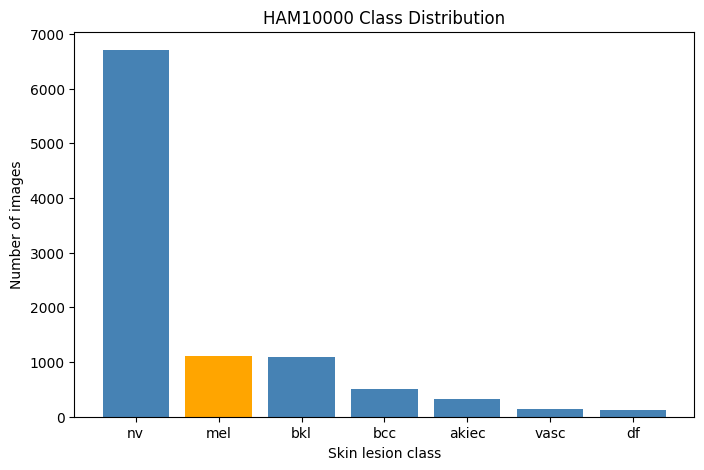

In [ ]:
# Count images in each class
counts = df["dx"].value_counts()

class_table = pd.DataFrame({
    "Class": counts.index,
    "Name": [FULL_NAMES[c] for c in counts.index],
    "Images": counts.values,
    "Percentage": (counts.values / len(df) * 100).round(2)
})

display(class_table)

# Check class imbalance
majority = counts.index[0]
majority_acc = counts.max() / len(df)
imbalance_ratio = counts.max() / counts.min()

print("Majority class:", majority)
print("Majority class accuracy:", round(majority_acc, 3))
print("Imbalance ratio:", round(imbalance_ratio, 1), ": 1")

# Plot class distribution
plt.figure(figsize=(8, 5))

colors = ["orange" if c == "mel" else "steelblue" for c in counts.index]

plt.bar(counts.index, counts.values, color=colors)

plt.xlabel("Skin lesion class")
plt.ylabel("Number of images")
plt.title("HAM10000 Class Distribution")

plt.savefig(FIG_DIR / "fig1_class_distribution.png")
plt.show()


### 2.2 Sample Images

This section displays five randomly selected images from each of the seven skin lesion classes to explore their visual appearance and differences.


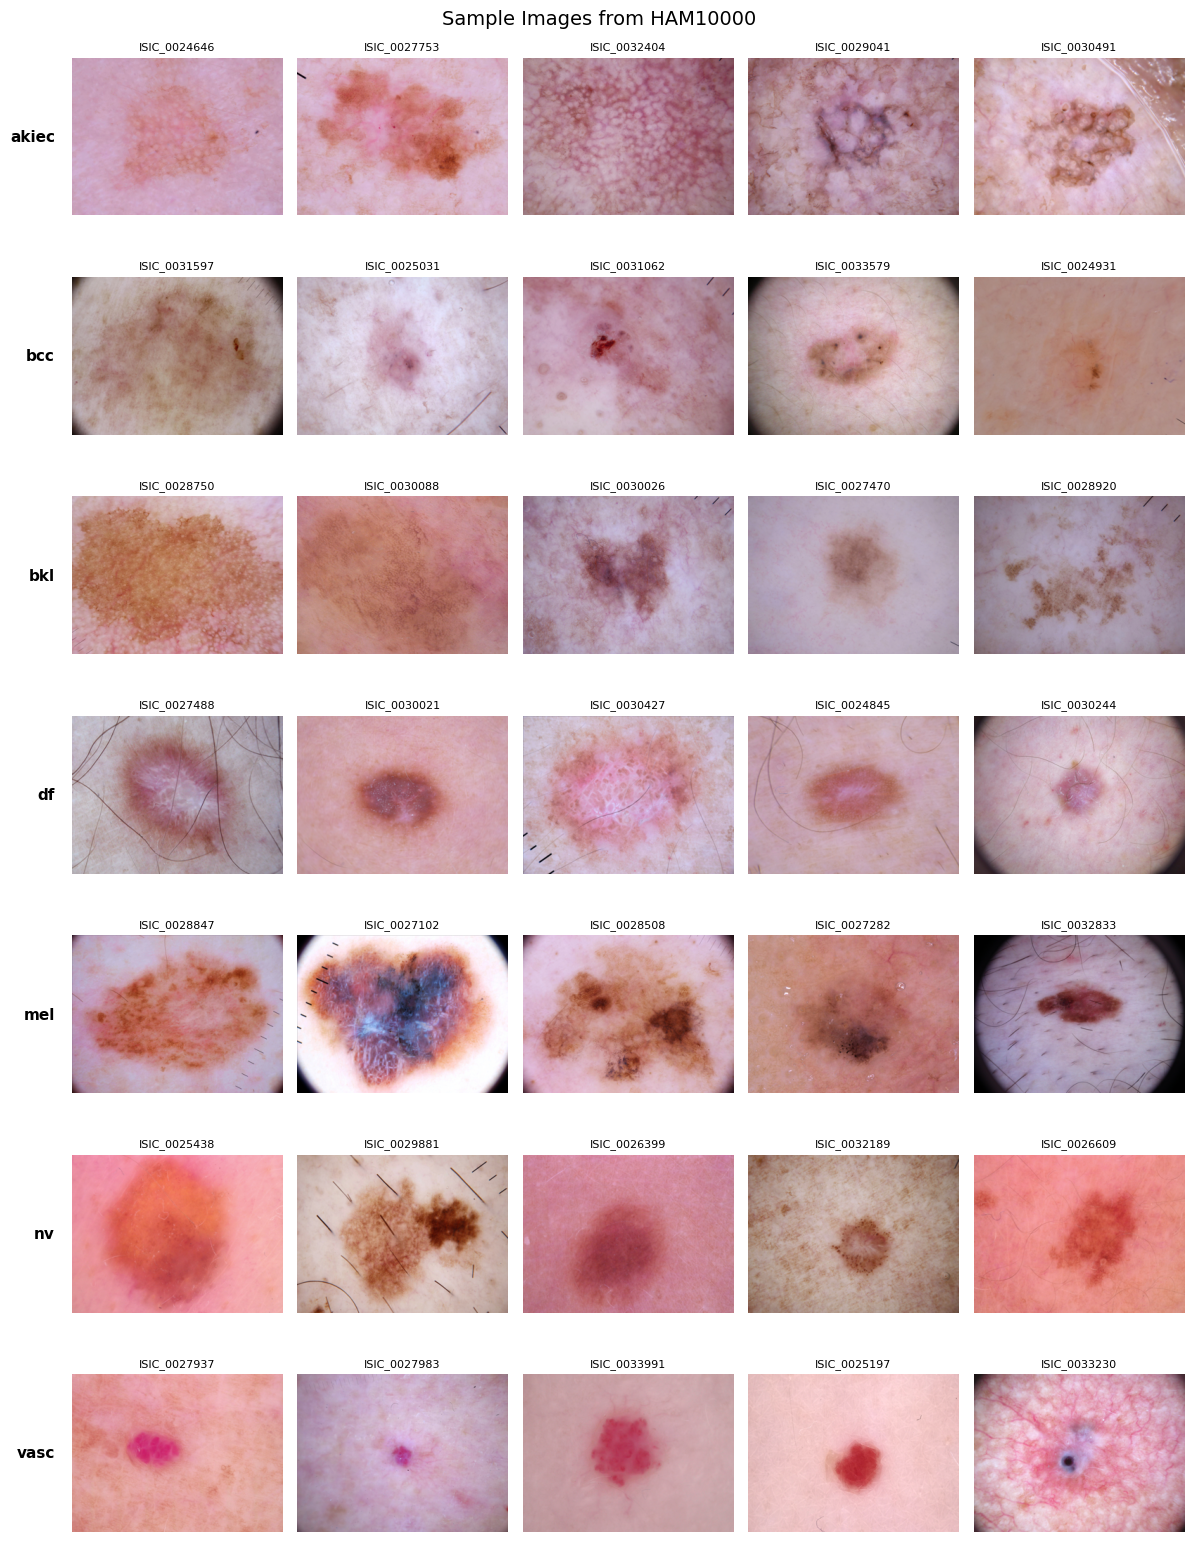

akiec : Actinic keratoses / intraepithelial carcinoma
bcc : Basal cell carcinoma
bkl : Benign keratosis-like lesions
df : Dermatofibroma
mel : Melanoma
nv : Melanocytic nevi
vasc : Vascular lesions


In [ ]:
# Display 5 sample images from each class
fig, axes = plt.subplots(7, 5, figsize=(12, 16))

for row, cls in enumerate(CLASS_NAMES):
    sample = df[df["dx"] == cls].sample(5, random_state=SEED)

    for col, (_, image) in enumerate(sample.iterrows()):
        with Image.open(image["path"]) as img:
            img = img.convert("RGB")
            img = img.resize((300, 225))

            axes[row, col].imshow(img)

        axes[row, col].axis("off")
        axes[row, col].set_title(image["image_id"], fontsize=8)

    # Display class name on the left
    axes[row, 0].text(
    -0.08, 0.5, cls,
    transform=axes[row, 0].transAxes,
    fontsize=11,
    fontweight="bold",
    ha="right",
    va="center"
)

plt.suptitle("Sample Images from HAM10000", fontsize=14)
plt.tight_layout()

plt.savefig(FIG_DIR / "fig2_sample_images.png", bbox_inches="tight")
plt.show()

# Display full class names
for cls, name in FULL_NAMES.items():
    print(cls, ":", name)


### 2.3 Metadata and Repeated Lesions

This section explores patient age, sex and lesion location. It also checks for missing values and identifies lesions with multiple images, which is important for preventing data leakage during dataset splitting.


In [ ]:
# Check patient information
df["age_num"] = pd.to_numeric(df["age"], errors="coerce")
df["sex_clean"] = df["sex"].replace({"unknown": np.nan})
df["loc_clean"] = df["localization"].replace({"unknown": np.nan})

# Check missing values
print("Missing ages:", df["age_num"].isna().sum())
print("Missing sex values:", df["sex_clean"].isna().sum())
print("Missing locations:", df["loc_clean"].isna().sum())

# Age information
print("Median age:", df["age_num"].median())
print("Minimum age:", df["age_num"].min())
print("Maximum age:", df["age_num"].max())

# Patient and diagnosis information
print("\nSex distribution:")
print(df["sex_clean"].value_counts(dropna=False))

print("\nMost common lesion locations:")
print(df["loc_clean"].value_counts().head(6))

print("\nDiagnosis confirmation methods:")
print(df["dx_type"].value_counts())

# Check repeated lesions
images_per_lesion = df.groupby("lesion_id").size()
repeated = images_per_lesion[images_per_lesion > 1]

print("\nTotal images:", len(df))
print("Unique lesions:", len(images_per_lesion))
print("Lesions with multiple images:", len(repeated))
print("Images from repeated lesions:", repeated.sum())
print("Maximum images per lesion:", images_per_lesion.max())

Missing ages: 57
Missing sex values: 57
Missing locations: 234
Median age: 50.0
Minimum age: 0.0
Maximum age: 85.0

Sex distribution:
sex_clean
male      5406
female    4552
NaN         57
Name: count, dtype: int64

Most common lesion locations:
loc_clean
back               2192
lower extremity    2077
trunk              1404
upper extremity    1118
abdomen            1022
face                745
Name: count, dtype: int64

Diagnosis confirmation methods:
dx_type
histo        5340
follow_up    3704
consensus     902
confocal       69
Name: count, dtype: int64

Total images: 10015
Unique lesions: 7470
Lesions with multiple images: 1956
Images from repeated lesions: 4501
Maximum images per lesion: 6



## Section 3 – Preprocessing and Data Splitting

### 3.1 Lesion-Level Data Splitting

The dataset is divided into 70% training, 15% validation and 15% testing using stratified lesion-level splitting.

Images belonging to the same lesion are kept in the same subset to prevent data leakage. The training set is used to train the model, validation is used to select the best model, and testing is used for final evaluation.

Since HAM10000 does not include patient IDs, complete patient-level separation cannot be guaranteed.

In [ ]:
# Check that each lesion has only one diagnosis
assert (df.groupby("lesion_id")["label"].nunique() == 1).all()

# Create a list of unique lesions
lesions = df.groupby("lesion_id", as_index=False).agg(
    label=("label", "first")
)

# Split into training (70%), validation (15%) and testing (15%)
train_lesions, remaining = train_test_split(
    lesions,
    test_size=0.30,
    stratify=lesions["label"],
    random_state=SEED
)

val_lesions, test_lesions = train_test_split(
    remaining,
    test_size=0.50,
    stratify=remaining["label"],
    random_state=SEED
)

# Assign each lesion to a dataset split
split_of_lesion = {}

for name, part in [
    ("train", train_lesions),
    ("val", val_lesions),
    ("test", test_lesions)
]:
    for lesion_id in part["lesion_id"]:
        split_of_lesion[lesion_id] = name

df["split"] = df["lesion_id"].map(split_of_lesion)

# Check for data leakage
train_ids = set(train_lesions["lesion_id"])
val_ids = set(val_lesions["lesion_id"])
test_ids = set(test_lesions["lesion_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)
assert df["split"].notna().all()
assert df["image_id"].is_unique

print("Data splitting completed")
print("No overlapping lesions between datasets")

# Save dataset splits
df[["image_id", "lesion_id", "dx", "split"]].to_csv(
    BASE / "outputs" / "splits.csv",
    index=False
)

# Show number of images in each split
summary = pd.crosstab(df["dx"], df["split"])
summary = summary.reindex(
    index=CLASS_NAMES,
    columns=["train", "val", "test"],
    fill_value=0
)

summary.loc["TOTAL"] = summary.sum()

display(summary)

print("Training images:", (df["split"] == "train").sum())
print("Validation images:", (df["split"] == "val").sum())
print("Testing images:", (df["split"] == "test").sum())

Data splitting completed
No overlapping lesions between datasets


split,train,val,test
dx,,,
akiec,222,53,52
bcc,361,82,71
bkl,772,160,167
df,71,24,20
mel,773,173,167
nv,4683,1018,1004
vasc,99,22,21
TOTAL,6981,1532,1502


Training images: 6981
Validation images: 1532
Testing images: 1502



### 3.2 Image Preprocessing and Augmentation

All images are resized to 224 × 224 pixels and normalized using the pretrained ViT model's settings.

During training, random flips, rotations and small brightness and contrast adjustments are applied to help reduce overfitting. Validation and test images are not augmented.

Both models use the same preprocessing and augmentation settings for a fair comparison. Images are resized once and cached to make training faster.

In [ ]:
# Load the pretrained ViT image settings
MODEL_NAME = "google/vit-base-patch16-224-in21k"

processor = ViTImageProcessor.from_pretrained(MODEL_NAME)

MEAN = torch.tensor(processor.image_mean).view(3, 1, 1)
STD = torch.tensor(processor.image_std).view(3, 1, 1)

print("Image size:", processor.size)
print("Mean:", processor.image_mean)
print("Standard deviation:", processor.image_std)

# Resize and save images
CACHE_FILE = BASE / "ham10000_224_uint8.npy"

if CACHE_FILE.exists():
    X_all = np.load(CACHE_FILE, mmap_mode="r")
    print("Images loaded:", X_all.shape)

else:
    X_all = np.zeros(
        (len(df), IMG_SIZE, IMG_SIZE, 3),
        dtype=np.uint8
    )

    for i, path in enumerate(df["path"]):
        with Image.open(path) as img:
            img = img.convert("RGB")
            img = img.resize(
                (IMG_SIZE, IMG_SIZE),
                Image.Resampling.BILINEAR
            )
            X_all[i] = np.array(img)

        if (i + 1) % 2000 == 0:
            print("Images processed:", i + 1, "/", len(df))

    np.save(CACHE_FILE, X_all)
    print("Images saved:", X_all.shape)

# Verify the image cache
assert X_all.shape == (len(df), IMG_SIZE, IMG_SIZE, 3), \
    "Image cache does not match the dataset"

assert X_all.dtype == np.uint8, \
    "Image cache must contain uint8 images"

print("Image preprocessing ready")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Image size: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
Mean: (0.5, 0.5, 0.5)
Standard deviation: (0.5, 0.5, 0.5)
Images processed: 2000 / 10015
Images processed: 4000 / 10015
Images processed: 6000 / 10015
Images processed: 8000 / 10015
Images processed: 10000 / 10015
Images saved: (10015, 224, 224, 3)
Image preprocessing ready



### 3.3 PyTorch Dataset and DataLoader

The PyTorch Dataset prepares images and their labels, while the DataLoader organizes them into batches for model training and validation.

Training images are augmented and normalized, while validation images are only normalized.

In [ ]:
USE_AUGMENTATION = True
BATCH_SIZE = 32

# Create the dataset
class HamDataset(Dataset):

    def __init__(self, frame, augment=False):
        self.rows = frame["row"].values
        self.labels = frame["label"].values
        self.augment = augment

        self.augmentation = T.Compose([
            T.RandomHorizontalFlip(),
            T.RandomVerticalFlip(),
            T.RandomRotation(20),
            T.ColorJitter(brightness=0.1, contrast=0.1)
        ])

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        image = torch.from_numpy(X_all[self.rows[i]])
        image = image.permute(2, 0, 1)

        if self.augment:
            image = self.augmentation(image)

        image = image.float() / 255
        image = (image - MEAN) / STD

        return image, int(self.labels[i])


# Split training and validation images
train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "val"]

# Use fewer images for quick testing
if QUICK_TEST:
    train_df = train_df.groupby("label", group_keys=False).head(40)
    val_df = val_df.groupby("label", group_keys=False).head(10)

# Create DataLoaders
train_generator = torch.Generator()
train_generator.manual_seed(SEED)

train_loader = DataLoader(
    HamDataset(train_df, augment=USE_AUGMENTATION),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    generator=train_generator
)

val_loader = DataLoader(
    HamDataset(val_df),
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Training batches:", len(train_loader))

# Check one batch
images, labels = next(iter(train_loader))

print("Batch shape:", images.shape)
print("Labels:", labels[:8].tolist())
print("Minimum pixel value:", round(images.min().item(), 2))
print("Maximum pixel value:", round(images.max().item(), 2))

Training images: 6981
Validation images: 1532
Training batches: 219
Batch shape: torch.Size([32, 3, 224, 224])
Labels: [5, 0, 5, 5, 5, 5, 5, 0]
Minimum pixel value: -1.0
Maximum pixel value: 1.0


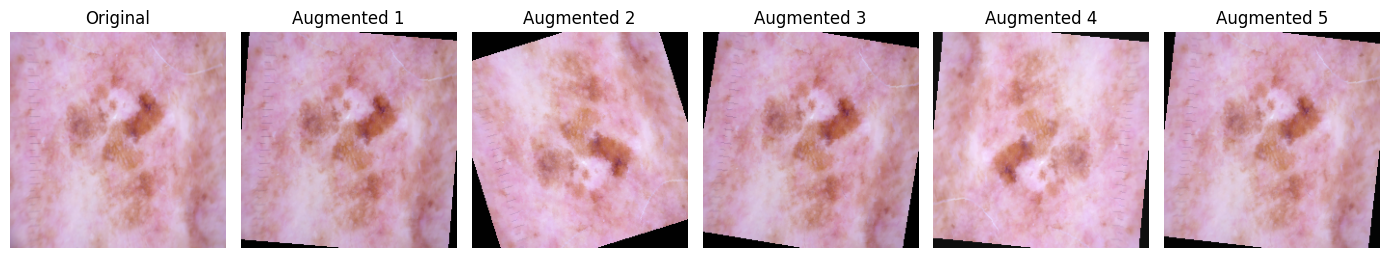

In [ ]:
# Show original and augmented images
demo_dataset = HamDataset(train_df.iloc[[0]], augment=True)

fig, axes = plt.subplots(1, 6, figsize=(14, 3))

# Original image
original = X_all[train_df.iloc[0]["row"]]
axes[0].imshow(original)
axes[0].set_title("Original")

# Augmented images
for i in range(1, 6):
    image, label = demo_dataset[0]

    # Convert image back to normal colours
    image = image * STD + MEAN
    image = image.clamp(0, 1)
    image = image.permute(1, 2, 0).numpy()

    axes[i].imshow(image)
    axes[i].set_title("Augmented " + str(i))

# Hide axes
for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig3_augmentation_preview.png")
plt.show()


## Section 4 – Model Selection

### 4.1 Vision Transformer (ViT)

A Vision Transformer divides an image into smaller patches and uses self-attention to learn relationships between different parts of the image.

For a 224 × 224 image, ViT-B/16 creates 196 patches of size 16 × 16. These patches are processed through Transformer layers to learn visual features for classification (Dosovitskiy et al., 2021).

### 4.2 Chosen Model

This project uses the pretrained `google/vit-base-patch16-224-in21k` model from Hugging Face.

The model was pretrained on ImageNet-21k and is adapted to classify the seven HAM10000 skin lesion categories.

Two approaches are compared:
- **Full fine-tuning:** All model parameters are updated during training.
- **Frozen backbone:** The pretrained ViT layers remain unchanged, and only the classification head is trained.

In [ ]:
# Load the pretrained Vision Transformer
def build_model():
    torch.manual_seed(SEED)

    model = ViTForImageClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(CLASS_NAMES),
        id2label=id2label,
        label2id=label2id,
        ignore_mismatched_sizes=True
    )

    return model.to(device)


model = build_model()

# Model configuration
cfg = model.config

total_params = sum(p.numel() for p in model.parameters())
head_params = sum(p.numel() for p in model.classifier.parameters())

print("Encoder layers:", cfg.num_hidden_layers)
print("Hidden size:", cfg.hidden_size)
print("Attention heads:", cfg.num_attention_heads)
print("Patch size:", cfg.patch_size)
print("Image size:", cfg.image_size)

print("Total parameters:", total_params)
print("Classification head parameters:", head_params)
print("Classification head:", model.classifier)

# Verify that the classification head has seven outputs
assert model.classifier.out_features == 7, \
    "Classification head must have 7 outputs"

del model
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Encoder layers: 12
Hidden size: 768
Attention heads: 12
Patch size: 16
Image size: 224
Total parameters: 85804039
Classification head parameters: 5383
Classification head: Linear(in_features=768, out_features=7, bias=True)



## Section 5 – Model Training

### 5.1 Training Configuration

Both models use class-weighted cross-entropy loss to address the imbalance between the seven skin lesion categories.

Training uses the AdamW optimizer, weight decay of 0.01, a cosine learning rate scheduler with warm-up, and a batch size of 32.

The fully fine-tuned model uses a learning rate of 2e-5, while the frozen ViT uses 1e-3 to train only its classification head.

Both models are trained for 10 epochs, and the best model is selected using validation macro-F1. Mixed precision and gradient clipping are used during training.

In [ ]:
# Training settings
EPOCHS = 1 if QUICK_TEST else 10
LR_FINETUNE = 2e-5
WEIGHT_DECAY = 0.01
USE_CLASS_WEIGHTS = True

# Calculate class weights using training data
train_counts = np.bincount(train_df["label"], minlength=7)

class_weights = torch.tensor(
    len(train_df) / (7 * train_counts),
    dtype=torch.float32
).to(device)

# Loss function
loss_fn = nn.CrossEntropyLoss(
    weight=class_weights if USE_CLASS_WEIGHTS else None
)

# Display class weights
weight_table = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Training Images": train_counts,
    "Class Weight": class_weights.cpu().numpy().round(2)
})

display(weight_table)

,Class,Training Images,Class Weight
0,akiec,222,4.49
1,bcc,361,2.76
2,bkl,772,1.29
3,df,71,14.05
4,mel,773,1.29
5,nv,4683,0.21
6,vasc,99,10.07


In [ ]:
# Evaluate the model
@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    total_loss = 0.0
    all_logits = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        with torch.autocast(device_type=device.type, enabled=use_amp):
            logits = model(pixel_values=images).logits

        total_loss += loss_fn(logits.float(), labels).item() * len(labels)

        all_logits.append(logits.float().cpu())
        all_labels.append(labels.cpu())

    logits = torch.cat(all_logits)
    labels = torch.cat(all_labels)

    probs = torch.softmax(logits, dim=1).numpy()

    return total_loss / len(labels), labels.numpy(), probs.argmax(axis=1), probs


# Train the model
def train_model(model, run_name, lr, epochs, train_loader, val_loader):

    trainable = [p for p in model.parameters() if p.requires_grad]

    optimizer = torch.optim.AdamW(
        trainable,
        lr=lr,
        weight_decay=WEIGHT_DECAY
    )

    total_steps = epochs * len(train_loader)

    scheduler = get_cosine_schedule_with_warmup(
        optimizer,
        int(0.1 * total_steps),
        total_steps
    )

    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    history = []
    best_f1 = -1.0
    best_epoch = 0

    # Use separate checkpoint files for quick and full runs
    run_type = "quick" if QUICK_TEST else "full"
    checkpoint_path = WEIGHTS_DIR / (run_name + "_" + run_type + "_best.pt")

    for epoch in range(1, epochs + 1):

        start = time.time()
        model.train()
        running_loss = 0.0

        for images, labels in train_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad()

            # Forward pass
            with torch.autocast(device_type=device.type, enabled=use_amp):
                logits = model(pixel_values=images).logits

            loss = loss_fn(logits.float(), labels)

            # Backward pass
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(trainable, 1.0)

            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            running_loss += loss.item() * len(labels)

        # Training and validation results
        train_loss = running_loss / len(train_loader.dataset)

        val_loss, y_val, pred_val, _ = evaluate(model, val_loader)

        val_f1 = f1_score(
            y_val,
            pred_val,
            average="macro",
            labels=range(7),
            zero_division=0
        )

        mel_recall = (
            ((pred_val == MEL) & (y_val == MEL)).sum()
            / max((y_val == MEL).sum(), 1)
        )

        val_accuracy = accuracy_score(y_val, pred_val)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "val_macro_f1": val_f1,
            "val_melanoma_recall": mel_recall
        })

        # Save the best model
        saved = False

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_epoch = epoch

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

            saved = True

        # Display training progress
        print("Model:", run_name)
        print("Epoch:", epoch, "/", epochs)
        print("Training loss:", round(train_loss, 3))
        print("Validation loss:", round(val_loss, 3))
        print("Validation accuracy:", round(val_accuracy, 3))
        print("Validation macro-F1:", round(val_f1, 3))
        print("Melanoma recall:", round(mel_recall, 3))
        print("Time:", round(time.time() - start), "seconds")

        if saved:
            print("Best model saved")

        print("------------------------")

    # Confirm the checkpoint exists
    assert checkpoint_path.exists(), "Model checkpoint was not saved"

    return pd.DataFrame(history), best_epoch


### 5.2 Fine-Tuning the Vision Transformer

This section trains the entire pretrained ViT model on HAM10000. All model parameters are updated during training.

Training and validation performance are monitored after each epoch, and the model with the highest validation macro-F1 is saved.

In [ ]:
# Load the model
model_ft = build_model()

# Check trainable parameters
trainable_params = sum(
    p.numel() for p in model_ft.parameters() if p.requires_grad
)

print("Trainable parameters (millions):", round(trainable_params / 1e6, 1))

# Reset random generator before training
train_generator.manual_seed(SEED)

# Train the model
history_ft, best_epoch_ft = train_model(
    model_ft,
    "finetuned",
    LR_FINETUNE,
    EPOCHS,
    train_loader,
    val_loader
)

print("Best epoch:", best_epoch_ft)

# Free GPU memory
del model_ft
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters (millions): 85.8
Model: finetuned
Epoch: 1 / 10
Training loss: 1.759
Validation loss: 1.341
Validation accuracy: 0.655
Validation macro-F1: 0.469
Melanoma recall: 0.699
Time: 69 seconds
Best model saved
------------------------
Model: finetuned
Epoch: 2 / 10
Training loss: 1.122
Validation loss: 0.977
Validation accuracy: 0.684
Validation macro-F1: 0.588
Melanoma recall: 0.85
Time: 70 seconds
Best model saved
------------------------
Model: finetuned
Epoch: 3 / 10
Training loss: 0.812
Validation loss: 0.791
Validation accuracy: 0.755
Validation macro-F1: 0.656
Melanoma recall: 0.676
Time: 75 seconds
Best model saved
------------------------
Model: finetuned
Epoch: 4 / 10
Training loss: 0.635
Validation loss: 0.845
Validation accuracy: 0.693
Validation macro-F1: 0.649
Melanoma recall: 0.879
Time: 78 seconds
------------------------
Model: finetuned
Epoch: 5 / 10
Training loss: 0.497
Validation loss: 0.723
Validation accuracy: 0.753
Validation macro-F1: 0.675
Melanom


## Section 6 – Baseline Model Comparison

This section trains a second ViT model as a baseline. Unlike the fully fine-tuned model, the pretrained ViT layers are frozen, and only the final classification layer is trained.

Both models use the same dataset splits, preprocessing, augmentation, loss function and training settings.

The fully fine-tuned model uses a learning rate of 2e-5, while the baseline uses 1e-3 because only its classification head is being trained.

The results will be compared to determine whether full fine-tuning improves skin lesion classification performance.

In [ ]:
# Learning rate for the classification head
LR_HEAD_ONLY = 1e-3

# Load the pretrained model
model_head = build_model()

# Freeze the pretrained ViT layers
for parameter in model_head.vit.parameters():
    parameter.requires_grad = False

# Check trainable parameters
trainable_params = sum(
    p.numel() for p in model_head.parameters() if p.requires_grad
)

print("Trainable parameters:", trainable_params)

# Check that only the classification head is trainable
trainable_names = [
    name for name, parameter in model_head.named_parameters()
    if parameter.requires_grad
]

assert all(
    name.startswith("classifier") for name in trainable_names
), "Only the classification head should be trainable"

# Reset random generator before training
train_generator.manual_seed(SEED)

# Train the classification head
history_head, best_epoch_head = train_model(
    model_head,
    "head_only",
    LR_HEAD_ONLY,
    EPOCHS,
    train_loader,
    val_loader
)

print("Best epoch:", best_epoch_head)

# Free GPU memory
del model_head
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 5383
Model: head_only
Epoch: 1 / 10
Training loss: 1.786
Validation loss: 1.652
Validation accuracy: 0.441
Validation macro-F1: 0.285
Melanoma recall: 0.688
Time: 43 seconds
Best model saved
------------------------
Model: head_only
Epoch: 2 / 10
Training loss: 1.379
Validation loss: 1.523
Validation accuracy: 0.458
Validation macro-F1: 0.351
Melanoma recall: 0.798
Time: 44 seconds
Best model saved
------------------------
Model: head_only
Epoch: 3 / 10
Training loss: 1.186
Validation loss: 1.312
Validation accuracy: 0.569
Validation macro-F1: 0.427
Melanoma recall: 0.699
Time: 45 seconds
Best model saved
------------------------
Model: head_only
Epoch: 4 / 10
Training loss: 1.088
Validation loss: 1.281
Validation accuracy: 0.564
Validation macro-F1: 0.422
Melanoma recall: 0.728
Time: 44 seconds
------------------------
Model: head_only
Epoch: 5 / 10
Training loss: 1.035
Validation loss: 1.188
Validation accuracy: 0.591
Validation macro-F1: 0.448
Melanoma recall: 


### 6.1 Optional Augmentation Experiment

This optional experiment compares fine-tuning with and without data augmentation to examine its effect on model performance.

Both versions use the same training settings and are compared using validation macro-F1.

The experiment is disabled by default (`RUN_AUGMENTATION_ABLATION = False`).

In [ ]:
# Optional experiment: training without augmentation
RUN_AUGMENTATION_ABLATION = False

if RUN_AUGMENTATION_ABLATION:

    # Create DataLoader without augmentation
    noaug_loader = DataLoader(
        HamDataset(train_df, augment=False),
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=True,
        generator=torch.Generator().manual_seed(SEED)
    )

    # Train another ViT model
    model_noaug = build_model()

    history_noaug, _ = train_model(
        model_noaug,
        "finetuned_noaug",
        LR_FINETUNE,
        EPOCHS,
        noaug_loader,
        val_loader
    )

    # Compare validation results
    with_aug = history_ft["val_macro_f1"].max()
    without_aug = history_noaug["val_macro_f1"].max()

    print("With augmentation:", round(with_aug, 3))
    print("Without augmentation:", round(without_aug, 3))

    # Free GPU memory
    del model_noaug
    torch.cuda.empty_cache()

else:
    print("Augmentation experiment skipped")

Augmentation experiment skipped



## Section 7 – Evaluation and Results

This section evaluates the fully fine-tuned ViT and the frozen ViT baseline using the test dataset. The test set is used only after training and model selection are complete.

### Evaluation Metrics

- **Accuracy:** Percentage of correctly classified images.
- **Precision:** How often predictions for a particular class are correct.
- **Recall:** How many actual images of a class are correctly identified.
- **F1-score:** Combines precision and recall into one measure.
- **Macro-F1:** Average F1-score across all seven classes, giving each class equal importance.
- **Melanoma recall:** Percentage of actual melanoma images correctly identified.
- **Confusion matrix:** Shows correct predictions and which skin lesion categories the models confuse.

Macro-F1 is the main evaluation metric because HAM10000 has an imbalanced class distribution.

In [ ]:
# Prepare the test dataset
test_df = df[df["split"] == "test"]

if QUICK_TEST:
    test_df = test_df.groupby("label", group_keys=False).head(10)

test_loader = DataLoader(
    HamDataset(test_df),
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Use the correct checkpoints
run_type = "quick" if QUICK_TEST else "full"

# Test both models
results = {}

for run_name in ["head_only", "finetuned"]:

    model = build_model()

    # Load the best checkpoint for this run
    weight_path = WEIGHTS_DIR / (run_name + "_" + run_type + "_best.pt")

    assert weight_path.exists(), "Missing checkpoint: " + str(weight_path)

    model.load_state_dict(
        torch.load(weight_path, map_location=device, weights_only=True)
    )

    # Make predictions
    _, y_true, y_pred, probs = evaluate(model, test_loader)

    results[run_name] = {
        "y_true": y_true,
        "y_pred": y_pred,
        "probs": probs
    }

    print("Test predictions completed:", run_name)

    # Free GPU memory
    del model
    torch.cuda.empty_cache()

# Show test dataset information
print("Test images:", len(test_df))
print("Unique test lesions:", test_df["lesion_id"].nunique())

# Check prediction order
assert (
    results["finetuned"]["y_true"] == test_df["label"].values
).all()

print("Test predictions match the dataset labels")

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Test predictions completed: head_only


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Test predictions completed: finetuned
Test images: 1502
Unique test lesions: 1121
Test predictions match the dataset labels


In [ ]:
# Calculate evaluation metrics
def metric_row(name, y_true, y_pred):

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=range(7),
        average="macro",
        zero_division=0
    )

    melanoma_total = (y_true == MEL).sum()
    melanoma_correct = ((y_true == MEL) & (y_pred == MEL)).sum()

    mel_recall = melanoma_correct / max(melanoma_total, 1)

    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_F1": f1,
        "melanoma_recall": mel_recall
    }


# Get the correct test labels
y_true = results["finetuned"]["y_true"]

# Reference model: always predict the majority class
majority_pred = np.full_like(y_true, label2id[majority])

# Compare the three approaches
comparison = pd.DataFrame([
    metric_row(
        "Reference: always predict " + majority,
        y_true,
        majority_pred
    ),
    metric_row(
        "ViT-B/16 head only (frozen backbone)",
        y_true,
        results["head_only"]["y_pred"]
    ),
    metric_row(
        "ViT-B/16 fully fine-tuned",
        y_true,
        results["finetuned"]["y_pred"]
    )
]).round(3)

if QUICK_TEST:
    print("QUICK TEST ONLY - Do not use these results in the report")

display(comparison)

# Display detailed results for both models
for run_name, title in [
    ("head_only", "HEAD ONLY (frozen backbone)"),
    ("finetuned", "FULLY FINE-TUNED")
]:

    print("\nPer-class report:", title)

    print(classification_report(
        y_true,
        results[run_name]["y_pred"],
        labels=range(7),
        target_names=CLASS_NAMES,
        digits=3,
        zero_division=0
    ))

# Save results
comparison.to_csv(
    BASE / "outputs" / "model_comparison.csv",
    index=False
)

,model,accuracy,macro_precision,macro_recall,macro_F1,melanoma_recall
0,Reference: always predict nv,0.668,0.095,0.143,0.114,0.000
1,ViT-B/16 head only (frozen backbone),0.598,0.441,0.610,0.489,0.593
2,ViT-B/16 fully fine-tuned,0.788,0.701,0.728,0.702,0.725



Per-class report: HEAD ONLY (frozen backbone)
              precision    recall  f1-score   support

       akiec      0.284     0.596     0.385        52
         bcc      0.426     0.690     0.527        71
         bkl      0.394     0.479     0.432       167
          df      0.189     0.350     0.246        20
         mel      0.277     0.593     0.378       167
          nv      0.947     0.610     0.742      1004
        vasc      0.571     0.952     0.714        21

    accuracy                          0.598      1502
   macro avg      0.441     0.610     0.489      1502
weighted avg      0.748     0.598     0.637      1502


Per-class report: FULLY FINE-TUNED
              precision    recall  f1-score   support

       akiec      0.477     0.808     0.600        52
         bcc      0.736     0.746     0.741        71
         bkl      0.639     0.563     0.599       167
          df      0.765     0.650     0.703        20
         mel      0.460     0.725     0.563      

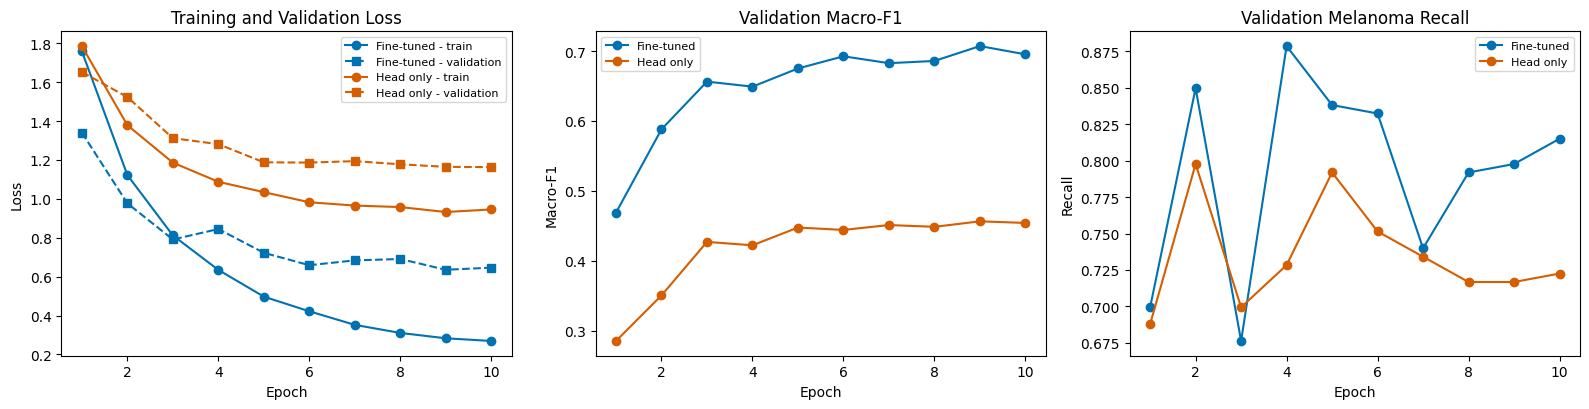

In [ ]:
# Plot training results
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

models = [
    (history_ft, "Fine-tuned", "#0072B2"),
    (history_head, "Head only", "#D55E00")
]

for history, name, color in models:

    # Training and validation loss
    axes[0].plot(
        history["epoch"],
        history["train_loss"],
        "o-",
        color=color,
        label=name + " - train"
    )

    axes[0].plot(
        history["epoch"],
        history["val_loss"],
        "s--",
        color=color,
        label=name + " - validation"
    )

    # Validation macro-F1
    axes[1].plot(
        history["epoch"],
        history["val_macro_f1"],
        "o-",
        color=color,
        label=name
    )

    # Melanoma recall
    axes[2].plot(
        history["epoch"],
        history["val_melanoma_recall"],
        "o-",
        color=color,
        label=name
    )

# Graph titles
axes[0].set_title("Training and Validation Loss")
axes[0].set_ylabel("Loss")

axes[1].set_title("Validation Macro-F1")
axes[1].set_ylabel("Macro-F1")

axes[2].set_title("Validation Melanoma Recall")
axes[2].set_ylabel("Recall")

# Format graphs
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig4_learning_curves.png")
plt.show()

# Save training history
history_ft.to_csv(
    BASE / "outputs" / "history_finetuned.csv",
    index=False
)

history_head.to_csv(
    BASE / "outputs" / "history_head_only.csv",
    index=False
)

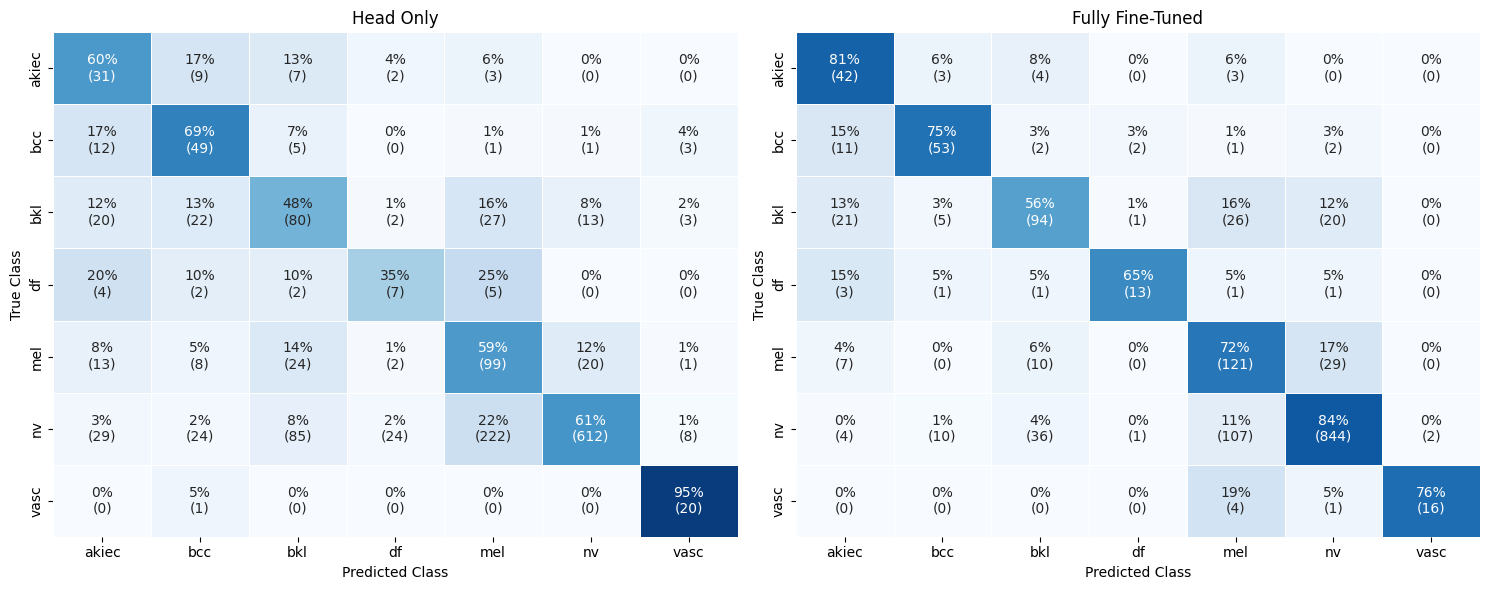

In [ ]:
# Plot confusion matrices for both models
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

models = [
    ("head_only", "Head Only"),
    ("finetuned", "Fully Fine-Tuned")
]

for ax, (run_name, title) in zip(axes, models):

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_true,
        results[run_name]["y_pred"],
        labels=range(7)
    )

    # Convert counts into percentages
    row_totals = cm.sum(axis=1, keepdims=True)
    cm_percent = np.divide(
        cm,
        row_totals,
        out=np.zeros_like(cm, dtype=float),
        where=row_totals != 0
    )

    # Display percentages and image counts
    text = []

    for i in range(7):
        row = []

        for j in range(7):
            percentage = round(cm_percent[i, j] * 100)
            row.append(str(percentage) + "%\n(" + str(cm[i, j]) + ")")

        text.append(row)

    # Create heatmap
    sns.heatmap(
        cm_percent,
        annot=np.array(text),
        fmt="",
        cmap="Blues",
        vmin=0,
        vmax=1,
        cbar=False,
        ax=ax,
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        linewidths=0.5
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig5_confusion_matrices.png")
plt.show()


### 7.1 Bootstrap Confidence Intervals

This section calculates 95% confidence intervals to estimate the uncertainty in model performance.

We use 1,000 bootstrap samples, randomly resampling whole lesions rather than individual images. Macro-F1 and melanoma recall are calculated for each sample.

The confidence intervals are also used to compare the fully fine-tuned ViT with the frozen ViT baseline.

In [ ]:
# Bootstrap settings
N_BOOT = 1000
rng = np.random.default_rng(SEED)

# Group test images by lesion
lesion_codes = test_df["lesion_id"].astype("category").cat.codes.values

images_of_lesion = [
    np.where(lesion_codes == i)[0]
    for i in range(lesion_codes.max() + 1)
]

# Calculate metrics
def boot_metrics(y, pred):

    macro_f1 = f1_score(
        y,
        pred,
        labels=range(7),
        average="macro",
        zero_division=0
    )

    melanoma_total = (y == MEL).sum()
    melanoma_correct = ((y == MEL) & (pred == MEL)).sum()

    mel_recall = melanoma_correct / max(melanoma_total, 1)

    return macro_f1, mel_recall


# Run bootstrap sampling
boot = {"head_only": [], "finetuned": []}

for i in range(N_BOOT):

    drawn = rng.integers(
        0,
        len(images_of_lesion),
        len(images_of_lesion)
    )

    idx = np.concatenate([images_of_lesion[k] for k in drawn])

    # Skip samples without melanoma images
    if (y_true[idx] == MEL).sum() == 0:
        continue

    for run_name in boot:
        scores = boot_metrics(
            y_true[idx],
            results[run_name]["y_pred"][idx]
        )

        boot[run_name].append(scores)

# Convert results to arrays
for run_name in boot:
    boot[run_name] = np.array(boot[run_name])

# Check that bootstrap samples were created
assert len(boot["head_only"]) > 0, "No valid bootstrap samples"

# Calculate differences between models
diff = boot["finetuned"] - boot["head_only"]


# Calculate 95% confidence intervals
def interval(values):

    low, high = np.percentile(values, [2.5, 97.5])

    return (
        str(round(values.mean(), 3))
        + " ["
        + str(round(low, 3))
        + ", "
        + str(round(high, 3))
        + "]"
    )


# Display confidence intervals
ci_table = pd.DataFrame({
    "macro-F1 (mean [95% CI])": [
        interval(boot["head_only"][:, 0]),
        interval(boot["finetuned"][:, 0]),
        interval(diff[:, 0])
    ],
    "melanoma recall (mean [95% CI])": [
        interval(boot["head_only"][:, 1]),
        interval(boot["finetuned"][:, 1]),
        interval(diff[:, 1])
    ]
}, index=[
    "head only",
    "fine-tuned",
    "difference (fine-tuned - head only)"
])

display(ci_table)

# Save interval limits for later analysis
ci_f1_low, ci_f1_high = np.percentile(diff[:, 0], [2.5, 97.5])
ci_mel_low, ci_mel_high = np.percentile(diff[:, 1], [2.5, 97.5])

# Save confidence intervals to Google Drive
output_path = BASE / "outputs" / "bootstrap_confidence_intervals.csv"

output_path.parent.mkdir(parents=True, exist_ok=True)

ci_table.to_csv(output_path, index_label="model")

print("Bootstrap results saved:", output_path)

,macro-F1 (mean [95% CI]),melanoma recall (mean [95% CI])
head only,"0.485 [0.442, 0.53]","0.593 [0.494, 0.685]"
fine-tuned,"0.699 [0.648, 0.749]","0.723 [0.632, 0.81]"
difference (fine-tuned - head only),"0.214 [0.154, 0.281]","0.13 [0.033, 0.234]"


Bootstrap results saved: /content/drive/MyDrive/HAM10000/outputs/bootstrap_confidence_intervals.csv



### 7.2 Example Predictions

This section displays examples of correct and incorrect predictions made by the fine-tuned ViT model.

It includes correctly classified images, incorrect predictions made with high confidence, and melanoma cases that the model failed to identify.

These examples help us understand the model's errors and limitations.

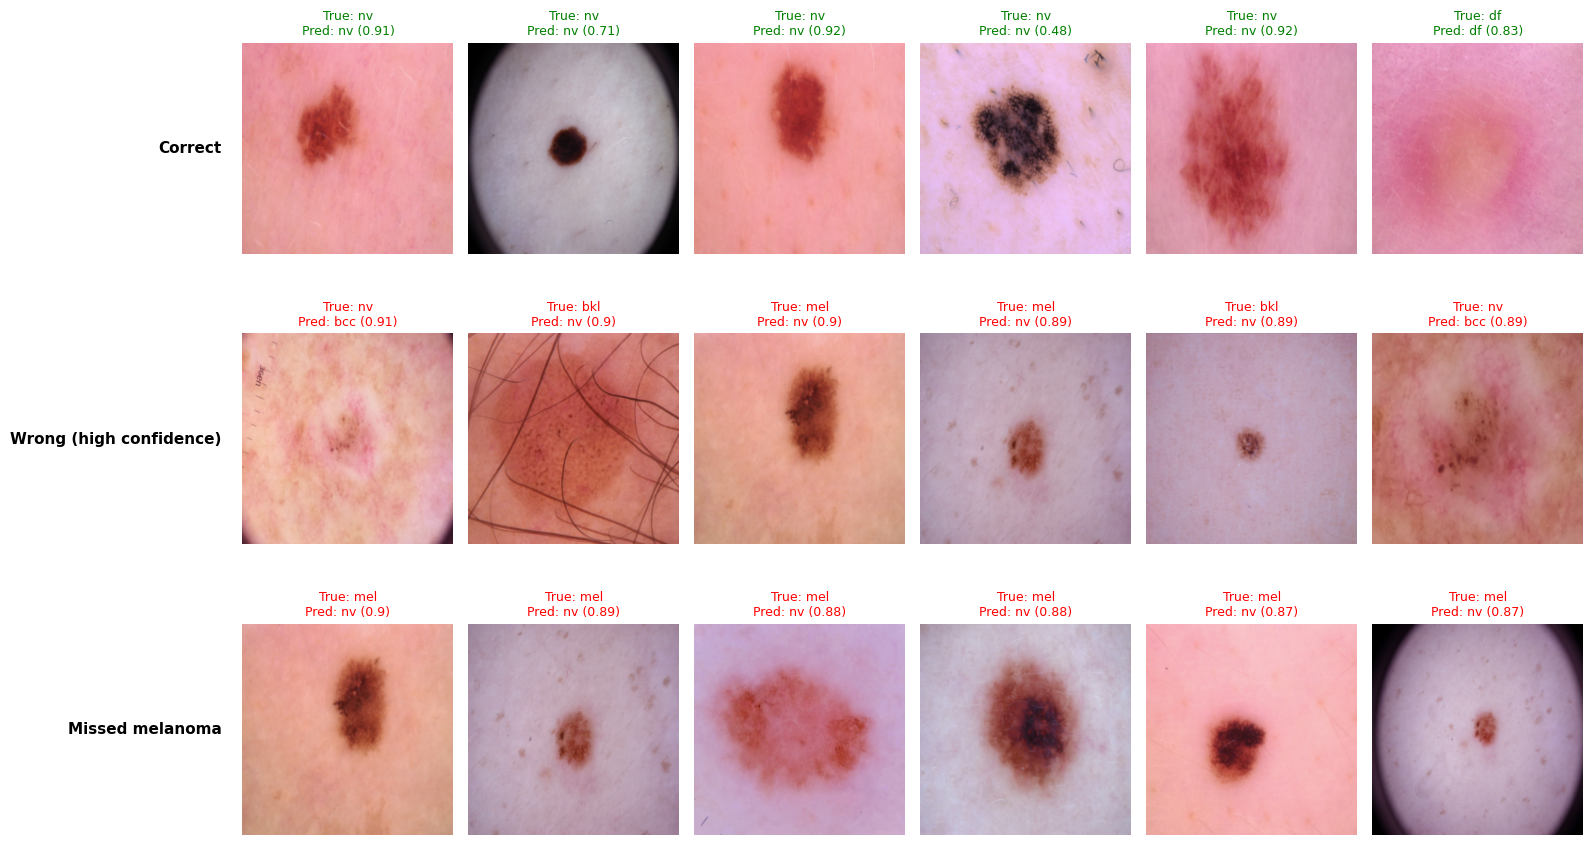

Total test images: 1502
Incorrect predictions: 319
Total melanoma images: 167
Missed melanoma cases: 46


In [ ]:
# Get model predictions and confidence scores
pred_ft = results["finetuned"]["y_pred"]
probs_ft = results["finetuned"]["probs"]

confidence = probs_ft.max(axis=1)
rng_show = np.random.default_rng(SEED)

# Find correct and incorrect predictions
correct = np.where(pred_ft == y_true)[0]
wrong = np.where(pred_ft != y_true)[0]

# Find missed melanoma cases
missed_mel = np.where(
    (y_true == MEL) & (pred_ft != MEL)
)[0]

# Choose examples to display
rows_to_show = [
    ("Correct", rng_show.choice(correct, size=min(6, len(correct)), replace=False)),
    ("Wrong (high confidence)", wrong[np.argsort(-confidence[wrong])][:6]),
    ("Missed melanoma", missed_mel[np.argsort(-confidence[missed_mel])][:6])
]

# Display images
fig, axes = plt.subplots(3, 6, figsize=(16, 9))

for row, (row_label, indices) in enumerate(rows_to_show):

    for col in range(6):
        ax = axes[row, col]
        ax.axis("off")

        if col < len(indices):
            i = indices[col]

            image = X_all[test_df.iloc[i]["row"]]
            ax.imshow(image)

            true_name = CLASS_NAMES[y_true[i]]
            predicted_name = CLASS_NAMES[pred_ft[i]]
            score = round(float(confidence[i]), 2)

            title = (
                "True: " + true_name
                + "\nPred: " + predicted_name
                + " (" + str(score) + ")"
            )

            color = "green" if pred_ft[i] == y_true[i] else "red"

            ax.set_title(title, fontsize=9, color=color)

    axes[row, 0].text(
        -0.1, 0.5, row_label,
        transform=axes[row, 0].transAxes,
        ha="right",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()
plt.savefig(FIG_DIR / "fig6_example_predictions.png")
plt.show()

# Summarise prediction errors
print("Total test images:", len(y_true))
print("Incorrect predictions:", len(wrong))
print("Total melanoma images:", (y_true == MEL).sum())
print("Missed melanoma cases:", len(missed_mel))


## Section 8 – Performance Analysis, Bias and Ethics

This section examines the model's performance across different skin lesion categories and discusses possible biases and limitations.

The analysis uses actual test results and dataset information. Other concerns, such as differences in performance across skin tones, are discussed as limitations because they cannot be directly evaluated using the available metadata.

### 8.1 Class Imbalance and Model Performance

This section compares the number of training images in each class with the model's precision, recall and F1-score.

It also compares recall between the fully fine-tuned ViT and the frozen baseline to identify which skin lesion categories are classified more accurately.

In [ ]:
# Calculate performance for each class
precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    results["finetuned"]["y_pred"],
    labels=range(7),
    zero_division=0
)

# Get recall scores for the frozen model
recall_head = precision_recall_fscore_support(
    y_true,
    results["head_only"]["y_pred"],
    labels=range(7),
    zero_division=0
)[1]

# Create per-class comparison table
class_analysis = pd.DataFrame({
    "class": CLASS_NAMES,
    "train_images": train_counts,
    "test_images": support,
    "precision (fine-tuned)": precision,
    "recall (fine-tuned)": recall,
    "F1 (fine-tuned)": f1,
    "recall (head only)": recall_head
})

class_analysis = class_analysis.sort_values(
    "train_images",
    ascending=False
).round(3)

if QUICK_TEST:
    print("QUICK TEST ONLY - Do not use these results in the report")

display(class_analysis)


# Find the most common classification mistakes
cm = confusion_matrix(
    y_true,
    results["finetuned"]["y_pred"],
    labels=range(7)
)

pairs = []

for i in range(7):
    for j in range(7):

        if i != j:
            count = cm[i, j]
            total = cm[i].sum()

            share = count / total if total > 0 else 0

            pairs.append([
                CLASS_NAMES[i],
                CLASS_NAMES[j],
                count,
                share
            ])

# Show the six most common mistakes
top_confusions = pd.DataFrame(
    pairs,
    columns=[
        "true class",
        "predicted as",
        "images",
        "share of true class"
    ]
)

top_confusions = top_confusions.sort_values(
    "images",
    ascending=False
).head(6)

top_confusions["share of true class"] = (
    top_confusions["share of true class"].round(3)
)

print("\nMost frequent mistakes (fine-tuned model):")
display(top_confusions)

# Save the per-class results
class_analysis.to_csv(
    BASE / "outputs" / "per_class_analysis.csv",
    index=False
)

,class,train_images,test_images,precision (fine-tuned),recall (fine-tuned),F1 (fine-tuned),recall (head only)
5,nv,4683,1004,0.941,0.841,0.888,0.610
4,mel,773,167,0.460,0.725,0.563,0.593
2,bkl,772,167,0.639,0.563,0.599,0.479
1,bcc,361,71,0.736,0.746,0.741,0.690
0,akiec,222,52,0.477,0.808,0.600,0.596
6,vasc,99,21,0.889,0.762,0.821,0.952
3,df,71,20,0.765,0.650,0.703,0.350



Most frequent mistakes (fine-tuned model):


,true class,predicted as,images,share of true class
34,nv,mel,107,0.107
32,nv,bkl,36,0.036
28,mel,nv,29,0.174
15,bkl,mel,26,0.156
12,bkl,akiec,21,0.126
16,bkl,nv,20,0.120



### 8.2 Performance by Patient Subgroups

This section compares the fine-tuned ViT model's performance across different sex and age groups using the test dataset.

Accuracy, balanced accuracy and melanoma recall are calculated for each group to identify possible differences in model performance.

Results should be interpreted carefully because some groups have fewer images or melanoma cases. Skin-tone performance cannot be evaluated because the dataset does not provide skin-tone labels.

In [ ]:
# Prepare test results for subgroup analysis
warnings.filterwarnings(
    "ignore",
    message=".*y_pred contains classes not in y_true.*"
)

test_eval = test_df.assign(
    true=y_true,
    pred=results["finetuned"]["y_pred"]
)

# Group by sex
test_eval["sex_group"] = (
    test_eval["sex_clean"].astype(object).fillna("missing")
)

# Group by age
test_eval["age_group"] = pd.cut(
    test_eval["age_num"],
    bins=[0, 20, 40, 60, 80, np.inf],
    right=False,
    labels=["0-19", "20-39", "40-59", "60-79", "80+"]
).astype(object).fillna("missing")


# Calculate subgroup performance
def subgroup_table(column):

    rows = []

    for value, group in test_eval.groupby(column):

        is_mel = group["true"] == MEL

        accuracy = (group["true"] == group["pred"]).mean()

        balanced_acc = balanced_accuracy_score(
            group["true"],
            group["pred"]
        )

        if is_mel.any():
            mel_recall = (group.loc[is_mel, "pred"] == MEL).mean()
        else:
            mel_recall = np.nan

        rows.append({
            column: value,
            "images": len(group),
            "lesions": group["lesion_id"].nunique(),
            "melanomas": int(is_mel.sum()),
            "accuracy": accuracy,
            "balanced_accuracy": balanced_acc,
            "melanoma_recall": mel_recall
        })

    return pd.DataFrame(rows).round(3)


# Create subgroup tables
subgroups = {
    "sex_group": subgroup_table("sex_group"),
    "age_group": subgroup_table("age_group")
}

if QUICK_TEST:
    print("QUICK TEST ONLY - Do not use these results in the report")

# Display and save results
for name, table in subgroups.items():

    print("\nPerformance by:", name)
    display(table)

    table.to_csv(
        BASE / "outputs" / ("subgroup_" + name + ".csv"),
        index=False
    )


Performance by: sex_group


,sex_group,images,lesions,melanomas,accuracy,balanced_accuracy,melanoma_recall
0,female,694,526,70,0.827,0.796,0.657
1,male,796,586,97,0.754,0.702,0.773
2,missing,12,9,0,0.750,0.750,NaN



Performance by: age_group


,age_group,images,lesions,melanomas,accuracy,balanced_accuracy,melanoma_recall
0,0-19,34,18,0,0.676,0.662,NaN
1,20-39,256,175,21,0.840,0.703,0.429
2,40-59,671,554,46,0.851,0.759,0.891
3,60-79,431,302,74,0.694,0.693,0.703
4,80+,101,64,26,0.673,0.637,0.731
5,missing,9,8,0,0.778,0.775,NaN



### 8.3 Dataset Limitations

This section examines class imbalance, missing metadata, repeated lesions and the number of test lesions in each category.

These findings help identify limitations of the HAM10000 dataset that may affect model evaluation and reliability.

In [ ]:
# Check available metadata
print("Metadata columns:", META_COLUMNS)

keywords = [
    "patient", "skin", "fitz", "tone", "ethnic",
    "race", "device", "camera", "source",
    "clinic", "centre", "center"
]

hints = []

for column in META_COLUMNS:
    if any(word in column.lower() for word in keywords):
        hints.append(column)

print("\nPatient, skin tone or image source columns:")
print(hints if hints else "None available")

# Check class imbalance
largest_class = counts.index[0]
smallest_class = counts.index[-1]

print("\nLargest class:", largest_class)
print("Percentage:", round(100 * counts.iloc[0] / len(df), 1), "%")

print("\nSmallest class:", smallest_class)
print("Images:", counts.iloc[-1])
print("Percentage:", round(100 * counts.iloc[-1] / len(df), 2), "%")

# Check missing information
print("\nMissing ages:", df["age_num"].isna().sum())
print("Missing sex values:", df["sex_clean"].isna().sum())
print("Missing locations:", df["loc_clean"].isna().sum())

# Diagnosis confirmation methods
print("\nDiagnosis confirmation methods (%):")
print((100 * df["dx_type"].value_counts(normalize=True)).round(1))

# Check repeated lesions
print("\nLesions with multiple images:", len(repeated))
print(
    "Percentage of lesions:",
    round(100 * len(repeated) / len(images_per_lesion), 1),
    "%"
)

# Check rare classes in the test set
test_lesion_counts = (
    test_df.groupby("dx")["lesion_id"]
    .nunique()
    .sort_values()
)

print("\nClasses with the fewest test lesions:")
print(test_lesion_counts.head(3))

Metadata columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

Patient, skin tone or image source columns:
None available

Largest class: nv
Percentage: 66.9 %

Smallest class: df
Images: 115
Percentage: 1.15 %

Missing ages: 57
Missing sex values: 57
Missing locations: 234

Diagnosis confirmation methods (%):
dx_type
histo        53.3
follow_up    37.0
consensus     9.0
confocal      0.7
Name: proportion, dtype: float64

Lesions with multiple images: 1956
Percentage of lesions: 26.2 %

Classes with the fewest test lesions:
dx
df       11
vasc     14
akiec    35
Name: lesion_id, dtype: int64



### 8.4 Discussion and Ethical Considerations

This section discusses the model's performance, limitations and potential ethical concerns.

**Class Imbalance:** HAM10000 contains unequal numbers of images across its seven classes. Per-class precision, recall and F1-score help assess how the model performs on common and rare categories.

**Model Performance:** The results are used to identify which lesion categories are classified accurately and which are frequently confused. Possible explanations include limited training examples and visual similarities between lesions.

**Melanoma Detection:** Melanoma recall is particularly important because missing a melanoma could delay medical treatment. The number of missed melanoma cases is also examined.

**Bias and Fairness:** Model performance is compared across sex and age groups. However, fairness across skin tones cannot be evaluated because the dataset does not provide skin-tone labels.

**Limitations:** The study uses one public dataset, has limited examples for some classes, and does not include external clinical validation. Patient-level independence also cannot be confirmed.

**Ethical Considerations:** Incorrect predictions, overreliance on AI, patient privacy and unequal performance across populations are important concerns.

**Future Improvements:** Further research could include more diverse datasets, external validation, additional fairness analysis and evaluation of prediction reliability.

This model is developed for academic research only and should not be used for clinical diagnosis.

In [ ]:
# Summarise model performance
if QUICK_TEST:
    print("QUICK TEST ONLY - Do not use these results in the report")

ft = comparison.iloc[2]
hd = comparison.iloc[1]
ref = comparison.iloc[0]

print("\nFine-tuned ViT:")
print("Macro-F1:", ft["macro_F1"])
print("Melanoma recall:", ft["melanoma_recall"])
print("Accuracy:", ft["accuracy"])

print("\nHead-only ViT:")
print("Macro-F1:", hd["macro_F1"])
print("Melanoma recall:", hd["melanoma_recall"])
print("Accuracy:", hd["accuracy"])

print("\nMajority-class reference:", majority)
print("Macro-F1:", ref["macro_F1"])
print("Accuracy:", ref["accuracy"])


# Interpret the confidence intervals
def verdict(low, high, metric):

    print("\nMetric:", metric)
    print("95% confidence interval:", round(low, 3), "to", round(high, 3))

    if low > 0:
        print("Fine-tuned model performed better based on this interval.")

    elif high < 0:
        print("Head-only model performed better based on this interval.")

    else:
        print("The interval includes zero, so the difference is uncertain.")


verdict(ci_f1_low, ci_f1_high, "Macro-F1")
verdict(ci_mel_low, ci_mel_high, "Melanoma recall")


# Check training and validation loss
best_row = history_ft.loc[
    history_ft["epoch"] == best_epoch_ft
].iloc[0]

print("\nBest fine-tuning epoch:", best_epoch_ft)
print("Training loss:", round(best_row["train_loss"], 3))
print("Validation loss:", round(best_row["val_loss"], 3))

if history_ft["val_loss"].iloc[-1] > 1.1 * history_ft["val_loss"].min():
    print("Validation loss increased after its minimum.")
    print("This may indicate overfitting in later epochs.")


# Check missed melanoma cases
print("\nTotal melanoma images:", (y_true == MEL).sum())
print("Missed melanoma cases:", len(missed_mel))



Fine-tuned ViT:
Macro-F1: 0.702
Melanoma recall: 0.725
Accuracy: 0.788

Head-only ViT:
Macro-F1: 0.489
Melanoma recall: 0.593
Accuracy: 0.598

Majority-class reference: nv
Macro-F1: 0.114
Accuracy: 0.668

Metric: Macro-F1
95% confidence interval: 0.154 to 0.281
Fine-tuned model performed better based on this interval.

Metric: Melanoma recall
95% confidence interval: 0.033 to 0.234
Fine-tuned model performed better based on this interval.

Best fine-tuning epoch: 9
Training loss: 0.283
Validation loss: 0.635

Total melanoma images: 167
Missed melanoma cases: 46



## Section 9 – Conclusion

This project evaluated a pretrained Vision Transformer (ViT-B/16) for classifying seven skin lesion categories in the HAM10000 dataset.

The fully fine-tuned model achieved 78.8% test accuracy and 0.702 macro-F1, outperforming the frozen-backbone baseline, which achieved 59.8% accuracy and 0.489 macro-F1. Melanoma recall also improved from 59.3% to 72.5%.

However, the model missed 46 of 167 melanoma images, highlighting important clinical safety limitations. Other limitations include class imbalance, limited demographic information, a single training seed and the absence of external clinical validation.

Future work could evaluate additional datasets, repeat training across multiple random seeds and investigate methods to improve melanoma detection.


## Section 10 – References

1. Tschandl, P., Rosendahl, C. and Kittler, H. (2018) 'The HAM10000 dataset, a large collection of multi-source dermatoscopic images of common pigmented skin lesions', *Scientific Data*, 5, 180161. https://doi.org/10.1038/sdata.2018.161

2. Dosovitskiy, A. et al. (2021) 'An image is worth 16x16 words: Transformers for image recognition at scale', *International Conference on Learning Representations*. https://openreview.net/forum?id=YicbFdNTTy

3. Google (n.d.) *ViT Base Patch16 224, pretrained on ImageNet-21k*. Hugging Face. https://huggingface.co/google/vit-base-patch16-224-in21k

4. Wolf, T. et al. (2020) 'Transformers: state-of-the-art natural language processing', *Proceedings of the 2020 Conference on Empirical Methods in Natural Language Processing: System Demonstrations*, pp. 38–45.

5. Paszke, A. et al. (2019) 'PyTorch: an imperative style, high-performance deep learning library', *Advances in Neural Information Processing Systems*, 32.

In [ ]:
# Save all results in a ZIP file
import shutil

zip_path = shutil.make_archive(
    str(BASE / "ham10000_vit_outputs"),
    "zip",
    BASE / "outputs"
)

print("ZIP file created:", zip_path)
print("File size (MB):", round(os.path.getsize(zip_path) / 1e6, 1))

# Warn if this was only a quick test
if QUICK_TEST:
    print("QUICK TEST ONLY - Do not use these results in the report")
    print("Set QUICK_TEST = False and rerun the notebook")

# Download the ZIP file from Google Colab
from google.colab import files
files.download(zip_path)

ZIP file created: /content/drive/MyDrive/HAM10000/ham10000_vit_outputs.zip
File size (MB): 20.4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>